# 4. Output sign changes

Does continued search delay recovery after only target output signs change?

Use the same target, noise, methods, and examples as notebook 3.
At example 50,000, reverse one of the two weights at each target output.
All target hidden weights, connections, and weight magnitudes stay fixed.

At the change, copy each proposed method and fix the copy's current connections.
This stops both connection changes and whole-unit replacement. Both copies still update all weights and step sizes.
They receive the same subsequent examples. The ideal reference also keeps its connections and learns its weights.

The comparison measures the combined cost of connection changes and whole-unit replacement.
Notebook 6 separates those operations from the same trained state.

Each method uses five seeds. The curves show mean RMSE without uncertainty bands.

With separate candidates, mean post-change RMSE is 0.220 with continued search and 0.219 with fixed connections.
Continued search reduces the initial error peak but delays the later return to low error.
Thus, the simpler change does not show a clear overall advantage for fixed connections across these five seeds.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
results = m.run_changed()


ideal: post-change RMSE 0.258


candidates: post-change RMSE 0.220


candidates_frozen: post-change RMSE 0.219


single: post-change RMSE 0.309


single_frozen: post-change RMSE 0.325


78.1s for 5 seeds per method


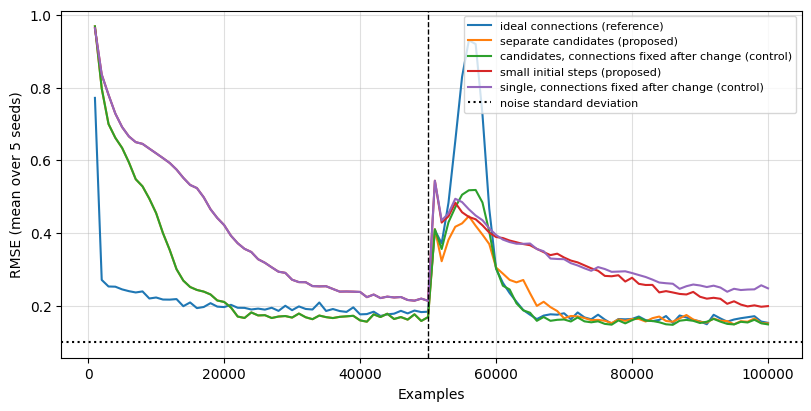

In [3]:
m.plot(results, changed=True)
